In [64]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.stats import jarque_bera
import matplotlib.pyplot as plt
from arch import arch_model

In [65]:
d = pd.read_csv('../Data/aggregation/BA_for_CG.csv')

In [66]:
df = d[['Date', 'Close']].copy()

In [67]:
df['r'] = np.log(df['Close'].shift(-1)/df['Close'])

In [68]:
df = df.dropna()

In [69]:
df.head(2)

,Date,Close,r
0,2016-01-04,140.500000,0.004049
1,2016-01-05,141.070007,-0.016006


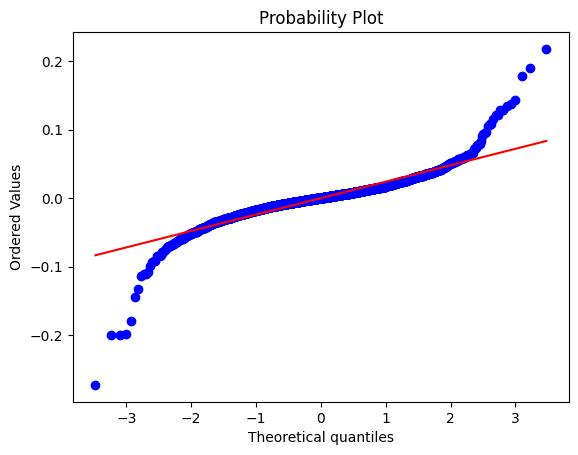

In [70]:
stats.probplot(df['r'], dist="norm", plot=plt)
plt.show()

In [71]:
stat, p = jarque_bera(df['r'])
print(f"JB={stat:.3f}, p={p:.4f}")

JB=27992.177, p=0.0000


Буду брать GARCH-t

In [72]:
df["Date"] = pd.to_datetime(df["Date"])
start = df["Date"].searchsorted(pd.Timestamp("2018-01-01"))
sigma = np.full(len(df), np.nan)

for i in range(start, len(df)):
    m = arch_model(100 * df["r"].iloc[:i], dist="t")
    fit = m.fit(disp="off") if (i - start) % 30 == 0 else m.fix(fit.params)
    sigma[i] = np.sqrt(fit.forecast().variance.iloc[-1, 0]) / 100

In [73]:
df["sigma_garch_t"] = sigma * np.sqrt(252)

In [74]:
d["Date"] = pd.to_datetime(d["Date"])
df["Date"] = pd.to_datetime(df["Date"])
d["sigma_garch_t"] = d["Date"].map(df.set_index("Date")["sigma_garch_t"])

In [75]:
d.to_csv('../Data/aggregation/BA_for_CG.csv', index=False)